Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ JSON inválido, se omite: matricula3.json (Expecting ',' delimiter: line 5 column 8 (char 60))
⚠️ JSON inválido, se omite: matricula5.json (Expecting ',' delimiter: line 5 column 7 (char 57))
⚠️ JSON inválido, se omite: matricula8.json (Expecting ',' delimiter: line 5 column 7 (char 58))
⚠️ JSON inválido, se omite: matricula9.json (Expecting ',' delimiter: line 5 column 7 (char 57))
JSON inválidos omitidos: 4
Imágenes seleccionadas: 100


Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.


Recortes de matrícula a evaluar: 201

[1/2] Ejecutando PaddleOCR...


Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/UVDoc`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


  PaddleOCR: 50/201
  PaddleOCR: 100/201
  PaddleOCR: 150/201
  PaddleOCR: 200/201
Resultados PaddleOCR recogidos: 201

[2/2] Ejecutando SmolVLM local...
Cargando SmolVLM (modelo ligero, debería ser rápido)...


/usr/local/lib/python3.13/dist-packages/transformers/models/auto/modeling_auto.py:2284: FutureWarning: The class `AutoModelForVision2Seq` is deprecated and will be removed in v5.0. Please use `AutoModelForImageTextToText` instead.
  warnings.warn(


  SmolVLM: 10/201
  SmolVLM: 20/201
  SmolVLM: 30/201
  SmolVLM: 40/201
  SmolVLM: 50/201
  SmolVLM: 60/201
  SmolVLM: 70/201
  SmolVLM: 80/201
  SmolVLM: 90/201
  SmolVLM: 100/201
  SmolVLM: 110/201
  SmolVLM: 120/201
  SmolVLM: 130/201
  SmolVLM: 140/201
  SmolVLM: 150/201
  SmolVLM: 160/201
  SmolVLM: 170/201
  SmolVLM: 180/201
  SmolVLM: 190/201
  SmolVLM: 200/201

PaddleOCR:
  Exact Match: 0.149 (14.9%)
  Char Accuracy: 0.432 (43.2%)
  Latencia mediana: 1799.8 ms
  Latencia P95: 4253.1 ms

SmolVLM (Local):
  Exact Match: 0.323 (32.3%)
  Char Accuracy: 0.490 (49.0%)
  Latencia mediana: 1745.7 ms
  Latencia P95: 2765.0 ms

✅ Resultados guardados en /content/comparativa/comparativa_ocr.pkl


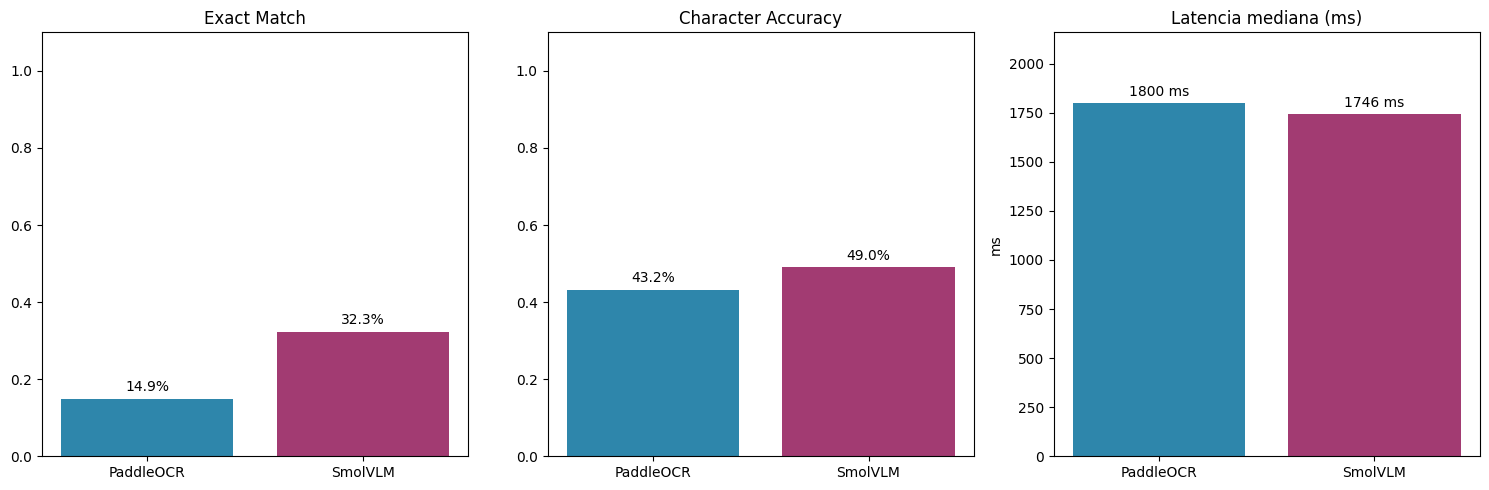

✅ Gráfica guardada en /content/comparativa/comparativa_ocr.png


In [ ]:
# 1. Montar Google Drive (opcional)
from google.colab import drive
drive.mount('/content/drive')

!pip install -q "transformers>=4.57,<4.58"

# 2. Instalar dependencias (si no las tienes)
# !pip install -q transformers accelerate torch paddlepaddle paddleocr

import json, time, random, re, pickle, os
from pathlib import Path
from PIL import Image
import numpy as np
from paddleocr import PaddleOCR
from difflib import SequenceMatcher
import matplotlib.pyplot as plt
import torch

# ================= CONFIG =================
ROOT = Path('/content/data_raw/Datos_P4_split/test')
X = 100
SEED = 42
random.seed(SEED)

OUT_DIR = Path('/content/comparativa')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============ 1. Seleccionar imágenes ============
candidatas = []
json_invalidos = []
for json_path in sorted((ROOT / 'annotations').glob('*.json')):
    try:
        with open(json_path, encoding='utf-8') as f:
            objs = json.load(f)
    except (json.JSONDecodeError, UnicodeDecodeError) as e:
        print(f'⚠️ JSON inválido, se omite: {json_path.name} ({e})')
        json_invalidos.append(json_path.name)
        continue

    if any(o.get('plate') not in (None, '') for o in objs):
        img_path = ROOT / 'images' / (json_path.stem + '.jpg')
        if img_path.exists():
            candidatas.append((img_path, json_path))

print(f'JSON inválidos omitidos: {len(json_invalidos)}')
muestra = random.sample(candidatas, min(X, len(candidatas)))
print(f'Imágenes seleccionadas: {len(muestra)}')

# ============ 2. Preparar recortes ============
recortes = []
for img_path, json_path in muestra:
    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    with open(json_path) as f:
        objs = json.load(f)
    for obj in objs:
        gt = obj.get('plate')
        if gt in (None, ''):
            continue
        xc, yc, w, h = obj['rectangle']
        x1 = max(0, int((xc - w/2) * W))
        y1 = max(0, int((yc - h/2) * H))
        x2 = min(W, int((xc + w/2) * W))
        y2 = min(H, int((yc + h/2) * H))
        if x2 - x1 < 10 or y2 - y1 < 5:
            continue
        crop = img.crop((x1, y1, x2, y2))
        recortes.append((img_path.name, gt.strip().upper(), crop))

print(f'Recortes de matrícula a evaluar: {len(recortes)}')

# ============ 3. PaddleOCR ============
print('\n[1/2] Ejecutando PaddleOCR...')
ocr = PaddleOCR(lang='es', use_textline_orientation=False, enable_mkldnn=False)

resultados_paddle = []
for i, (img_name, gt, crop) in enumerate(recortes):
    t0 = time.perf_counter()
    try:
        res = ocr.predict(np.array(crop))
        pred = ''
        if res:
            r0 = res[0]
            textos = r0.get('rec_texts', []) if isinstance(r0, dict) else getattr(r0, 'rec_texts', [])
            if textos:
                pred = str(textos[0]).strip().upper()
    except Exception as e:
        print(f'  PaddleOCR error en {img_name}: {e}')
        pred = ''
    t1 = time.perf_counter()
    resultados_paddle.append({'gt': gt, 'pred': pred, 'time': t1 - t0})
    if (i+1) % 50 == 0:
        print(f'  PaddleOCR: {i+1}/{len(recortes)}')

print(f'Resultados PaddleOCR recogidos: {len(resultados_paddle)}')

# ============ 4. SmolVLM local ============
print('\n[2/2] Ejecutando SmolVLM local...')
resultados_smolvlm = []

try:
    from transformers import AutoProcessor, AutoModelForVision2Seq
    from transformers.image_utils import load_image

    model_name = "HuggingFaceTB/SmolVLM-256M-Instruct"
    print("Cargando SmolVLM (modelo ligero, debería ser rápido)...")

    processor = AutoProcessor.from_pretrained(model_name)
    model = AutoModelForVision2Seq.from_pretrained(
        model_name,
        torch_dtype=torch.bfloat16,
        device_map="auto"
    ).eval()

    def call_smolvlm(crop, model, processor):
        # Guardar el recorte temporalmente o pasarlo directamente como PIL Image
        # SmolVLM acepta PIL Image directamente en el processor
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": "What is the license plate number in this image? Answer only the plate characters, no extra text."}
                ]
            }
        ]

        t0 = time.perf_counter()
        try:
            # Aplicar plantilla de chat
            prompt = processor.apply_chat_template(messages, add_generation_prompt=True)

            # Preparar inputs: pasamos la imagen PIL directamente
            inputs = processor(text=prompt, images=[crop], return_tensors="pt")
            inputs = inputs.to(model.device)

            # Generar
            generated_ids = model.generate(**inputs, max_new_tokens=30)

            # Decodificar solo la parte generada (no el prompt)
            generated_text = processor.batch_decode(
                generated_ids[:, inputs["input_ids"].shape[1]:],
                skip_special_tokens=True
            )[0]

            # Limpiar: mayúsculas, solo letras/números/guiones
            pred_clean = re.sub(r'[^A-Z0-9\-]', '', generated_text.strip().upper())
        except Exception as e:
            print(f"Error en inferencia SmolVLM: {e}")
            pred_clean = ''
        t1 = time.perf_counter()

        return pred_clean, t1 - t0

    for i, (img_name, gt, crop) in enumerate(recortes):
        pred, dt = call_smolvlm(crop, model, processor)
        resultados_smolvlm.append({'gt': gt, 'pred': pred, 'time': dt})
        if (i+1) % 10 == 0:
            print(f'  SmolVLM: {i+1}/{len(recortes)}')
            torch.cuda.empty_cache()

except Exception as e:
    print(f"\n❌ No se pudo cargar/ejecutar SmolVLM: {e}")
    print("Se continuará solo con los resultados de PaddleOCR.")

# ============ 5. Métricas ============
def exact_match(gt, pred):
    return int(gt == pred)

def char_accuracy(gt, pred):
    return SequenceMatcher(None, gt, pred).ratio()

def resumen(nombre, res):
    if not res:
        print(f'\n{nombre}: ⚠️ lista vacía, nada que calcular')
        return {'em': 0.0, 'ca': 0.0, 't_med': 0.0, 't_p95': 0.0}
    em = np.mean([exact_match(r['gt'], r['pred']) for r in res])
    ca = np.mean([char_accuracy(r['gt'], r['pred']) for r in res])
    t_med = np.median([r['time'] for r in res])
    t_p95 = np.percentile([r['time'] for r in res], 95)
    print(f'\n{nombre}:')
    print(f'  Exact Match: {em:.3f} ({em*100:.1f}%)')
    print(f'  Char Accuracy: {ca:.3f} ({ca*100:.1f}%)')
    print(f'  Latencia mediana: {t_med*1000:.1f} ms')
    print(f'  Latencia P95: {t_p95*1000:.1f} ms')
    return {'em': em, 'ca': ca, 't_med': t_med, 't_p95': t_p95}

r_paddle = resumen('PaddleOCR', resultados_paddle)
r_smolvlm = resumen('SmolVLM (Local)', resultados_smolvlm)

# Guardar resultados
with open(OUT_DIR / 'comparativa_ocr.pkl', 'wb') as f:
    pickle.dump({'paddle': resultados_paddle, 'smolvlm': resultados_smolvlm}, f)

print(f'\n✅ Resultados guardados en {OUT_DIR / "comparativa_ocr.pkl"}')

# ============ 6. Gráficas ============
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Exact Match
axes[0].bar(['PaddleOCR', 'SmolVLM'], [r_paddle['em'], r_smolvlm['em']], color=['#2E86AB', '#A23B72'])
axes[0].set_title('Exact Match')
axes[0].set_ylim(0, 1.1)
for i, v in enumerate([r_paddle['em'], r_smolvlm['em']]):
    axes[0].text(i, v + 0.02, f'{v:.1%}', ha='center')

# Char Accuracy
axes[1].bar(['PaddleOCR', 'SmolVLM'], [r_paddle['ca'], r_smolvlm['ca']], color=['#2E86AB', '#A23B72'])
axes[1].set_title('Character Accuracy')
axes[1].set_ylim(0, 1.1)
for i, v in enumerate([r_paddle['ca'], r_smolvlm['ca']]):
    axes[1].text(i, v + 0.02, f'{v:.1%}', ha='center')

# Latencia mediana
t_paddle_ms = r_paddle['t_med'] * 1000
t_smolvlm_ms = r_smolvlm['t_med'] * 1000
axes[2].bar(['PaddleOCR', 'SmolVLM'], [t_paddle_ms, t_smolvlm_ms], color=['#2E86AB', '#A23B72'])
axes[2].set_title('Latencia mediana (ms)')
axes[2].set_ylabel('ms')
max_t = max(t_paddle_ms, t_smolvlm_ms)
if max_t > 0:
    axes[2].set_ylim(0, max_t * 1.2)
for i, v in enumerate([t_paddle_ms, t_smolvlm_ms]):
    axes[2].text(i, v + (max_t*0.02), f'{v:.0f} ms', ha='center')

plt.tight_layout()
plt.savefig(OUT_DIR / 'comparativa_ocr.png', dpi=150)
plt.show()
print(f'✅ Gráfica guardada en {OUT_DIR / "comparativa_ocr.png"}')